# EDA: campañas de marketing de un banco portugués

Análisis exploratorio de datos sobre llamadas de marketing de un depósito a plazo. El notebook limpia y une los dos datasets, y analiza qué factores influyen en que un cliente suscriba.


## 1. Carga de datos


In [65]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Carpeta donde se guardan los gráficos
os.makedirs('../graficos', exist_ok=True)


In [66]:
# Dataset principal
bank = pd.read_csv('../raw/bank-additional.csv')

# Excel con 3 hojas, una por año de alta de los clientes
hojas = pd.read_excel('../raw/customer-details.xlsx', sheet_name=None)
customers = pd.concat(hojas.values(), ignore_index=True)

# Primer vistazo
print(bank.shape, customers.shape)
bank.head()


(43000, 24) (43170, 7)


,Unnamed: 0,age,job,marital,education,default,housing,loan,contact,duration,...,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,latitude,longitude,id_
0,0,NaN,housemaid,MARRIED,basic.4y,0.0,0.0,0.0,telephone,261,...,1.1,"93,994","-36,4","4,857",5191,no,2-agosto-2019,41.495,-71.233,089b39d8-e4d0-461b-87d4-814d71e0e079
1,1,57.0,services,MARRIED,high.school,NaN,0.0,0.0,telephone,149,...,1.1,"93,994","-36,4",NaN,5191,no,14-septiembre-2016,34.601,-83.923,e9d37224-cb6f-4942-98d7-46672963d097
2,2,37.0,services,MARRIED,high.school,0.0,1.0,0.0,telephone,226,...,1.1,"93,994","-36,4","4,857",5191,no,15-febrero-2019,34.939,-94.847,3f9f49b5-e410-4948-bf6e-f9244f04918b
3,3,40.0,admin.,MARRIED,basic.6y,0.0,0.0,0.0,telephone,151,...,1.1,"93,994","-36,4",NaN,5191,no,29-noviembre-2015,49.041,-70.308,9991fafb-4447-451a-8be2-b0df6098d13e
4,4,56.0,services,MARRIED,high.school,0.0,0.0,1.0,telephone,307,...,1.1,"93,994","-36,4",NaN,5191,no,29-enero-2017,38.033,-104.463,eca60b76-70b6-4077-80ba-bc52e8ebb0eb


Se comprueba que las claves de unión (`id_` en bank, `ID` en customers) no tienen duplicados y son del mismo tipo.


In [67]:
# ¿Hay duplicados en la clave de cada dataset?
print("Duplicados en bank['id_']:", bank['id_'].duplicated().sum())
print("Duplicados en customers['ID']:", customers['ID'].duplicated().sum())

# ¿Mismo tipo de dato en ambas claves?
print("Tipo id_:", bank['id_'].dtype)
print("Tipo ID:", customers['ID'].dtype)

Duplicados en bank['id_']: 0
Duplicados en customers['ID']: 0
Tipo id_: str
Tipo ID: str


## 2. Limpieza de bank

### 2.1 Columna sobrante y conversión de números
Se elimina `Unnamed: 0` (índice sobrante del CSV). Cuatro columnas numéricas vienen como texto con coma decimal (`"93,994"`) y se convierten a número.


In [68]:
bank = bank.drop(columns=['Unnamed: 0'])


In [69]:
columnas_coma = ['cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

for col in columnas_coma:
    bank[col] = pd.to_numeric(bank[col].str.replace(',', '.'))


### 2.2 Categorías y valores nulos
Se unifica el texto en minúsculas (`marital` y `poutcome` venían en mayúsculas). Los nulos de las columnas de texto no se rellenan con un valor inventado, sino con `unknown`. Las columnas `default`, `housing` y `loan`, codificadas como 0/1, se traducen a `no`/`yes` y sus nulos pasan también a `unknown`.


In [70]:
# Texto en minúsculas, igual que el resto de categóricas
for col in ['marital', 'poutcome']:
    bank[col] = bank[col].str.lower()


In [71]:
# Nulos en columnas de texto: se marcan como 'unknown'
for col in ['job', 'education', 'marital']:
    bank[col] = bank[col].fillna('unknown')


In [72]:
# Columnas 0/1 a no/yes; los nulos pasan a 'unknown'
traduccion = {0.0: 'no', 1.0: 'yes'}

for col in ['default', 'housing', 'loan']:
    bank[col] = bank[col].map(traduccion).fillna('unknown')


### 2.3 Edad
`age` tiene 5.120 nulos (12 %). Se rellenan con la mediana (38 años). Antes de rellenar se guarda una marca (`edad_imputada`) que indica qué edades eran nulas, para poder analizar después solo las edades reales.


In [73]:
bank['edad_imputada'] = bank['age'].isna()
bank['age'] = bank['age'].fillna(bank['age'].median()).astype(int)


### 2.4 Fechas
`date` viene como texto en español (`2-agosto-2019`). Python no entiende los nombres de mes en español, así que se traduce el mes a su número con un diccionario y después se convierte a fecha real. De ahí se obtienen `contact_month` y `contact_year`. Los 248 nulos de `date` (0,6 %) se conservan.


In [74]:
meses = {
    'enero': '1', 'febrero': '2', 'marzo': '3', 'abril': '4',
    'mayo': '5', 'junio': '6', 'julio': '7', 'agosto': '8',
    'septiembre': '9', 'octubre': '10', 'noviembre': '11', 'diciembre': '12'
}

partes = bank['date'].str.split('-', expand=True)



In [75]:
bank['date'] = partes[0] + '-' + partes[1].map(meses) + '-' + partes[2]

bank['date'] = pd.to_datetime(bank['date'], format='%d-%m-%Y')


In [76]:
bank['contact_year'] = bank['date'].dt.year
bank['contact_month'] = bank['date'].dt.month


### 2.5 Indicadores económicos
`euribor3m` tiene un 21,5 % de nulos. Se comprueba si otras variables económicas determinan su valor y no es así (dentro de cada grupo aparecen entre 7 y 21 valores distintos), por lo que **no se imputa**.

`cons.price.idx` tiene 471 nulos. Aquí sí: dentro de cada grupo de (`emp.var.rate`, `nr.employed`, `cons.conf.idx`) solo hay un valor, así que cada nulo se rellena con el valor de su grupo.


In [77]:
grupos = bank.groupby(['emp.var.rate', 'nr.employed'])['euribor3m'].nunique()
print(grupos.value_counts())


euribor3m
52    2
7     2
40    1
13    1
46    1
35    1
42    1
28    1
19    1
Name: count, dtype: int64


In [78]:
grupos = bank.groupby(['emp.var.rate', 'nr.employed', 'cons.conf.idx'])['euribor3m'].nunique()
print(grupos.value_counts())
print(len(grupos))


euribor3m
7     3
21    3
17    3
13    3
14    3
10    2
11    2
16    1
15    1
12    1
20    1
19    1
18    1
8     1
Name: count, dtype: int64
26


In [79]:
grupos = bank.groupby(['emp.var.rate', 'nr.employed', 'cons.conf.idx'])['cons.price.idx'].nunique()
print(grupos.value_counts())


cons.price.idx
1    26
Name: count, dtype: int64


In [80]:
valor_grupo = bank.groupby(['emp.var.rate', 'nr.employed', 'cons.conf.idx'])['cons.price.idx'].transform('first')


In [81]:
bank['cons.price.idx'] = bank['cons.price.idx'].fillna(valor_grupo)


### 2.6 pdays
`pdays` vale 999 en 41.412 filas (96 %). No es una cantidad de días, sino una marca de «nunca contactado antes»: aparece en todos los clientes con `poutcome = nonexistent` y en ninguno con `success`. Se sustituye por nulo y se crea la columna `contactado_antes` para no perder esa información.


In [82]:
print((bank['pdays'] == 999).sum())
print(bank.groupby('poutcome')['pdays'].apply(lambda s: (s == 999).sum()))


41412
poutcome
failure         4309
nonexistent    37103
success            0
Name: pdays, dtype: int64


In [83]:
bank['contactado_antes'] = bank['pdays'] != 999
bank['pdays'] = bank['pdays'].replace(999, np.nan)


## 3. Limpieza de customers

El Excel no tiene nulos, los tipos son correctos (`Dt_Customer` ya es fecha) y las distribuciones no muestran valores imposibles. Solo hay que eliminar la columna `Unnamed: 0`, igual que en `bank`.


In [84]:
customers = customers.drop(columns=['Unnamed: 0'])


## 4. Unión y guardado

Antes de unir se comprueba cuántos clientes coinciden en los dos datasets: las 43.000 llamadas de `bank` tienen su cliente en `customers` (los 170 clientes restantes no tienen llamada). Se une con `how='left'` para conservar todas las filas de `bank`, y `validate='one_to_one'` garantiza que ninguna clave se repite. El resultado se guarda en `procesado/bank_clean.csv`.


In [85]:
print(bank['id_'].isin(customers['ID']).sum())
print(customers['ID'].isin(bank['id_']).sum())


43000
43000


In [86]:
df = bank.merge(customers, left_on='id_', right_on='ID', how='left', validate='one_to_one')
df = df.drop(columns=['ID'])
print(df.shape)



(43000, 32)


In [87]:
df.to_csv('../procesado/bank_clean.csv', index=False)


## 5. Análisis descriptivo

Solo el 11,3 % de los clientes suscribe el depósito. Se comparan después las tasas de suscripción por tipo de cliente. La columna `suscribe` (1 si `y` es `yes`, 0 si no) permite calcular esa tasa como una media.


In [88]:
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True))


y
no     38156
yes     4844
Name: count, dtype: int64
y
no     0.887349
yes    0.112651
Name: proportion, dtype: float64


In [89]:
df['suscribe'] = (df['y'] == 'yes').astype(int)
print(df['suscribe'].mean())




0.11265116279069767


In [90]:
def tasa_por(columna):
    return df.groupby(columna)['suscribe'].agg(['mean', 'count']).sort_values('mean', ascending=False)


In [91]:
for columna in ['contact', 'job', 'education', 'marital', 'poutcome', 'default', 'housing', 'loan']:
    print(tasa_por(columna))
    print()


               mean  count
contact                   
cellular   0.147430  27396
telephone  0.051589  15604

                   mean  count
job                           
student        0.313400    903
retired        0.251955   1790
unemployed     0.143932   1063
admin.         0.130139  10873
unknown        0.113043    345
management     0.112131   3050
technician     0.108454   7026
self-employed  0.108126   1489
housemaid      0.098842   1123
entrepreneur   0.082786   1522
services       0.080730   4162
blue-collar    0.068883   9654

                         mean  count
education                           
illiterate           0.222222     18
unknown              0.144438   1807
university.degree    0.137400  12722
professional.course  0.113201   5477
high.school          0.108413   9925
basic.4y             0.102847   4356
basic.6y             0.081308   2386
basic.9y             0.078142   6309

              mean  count
marital                  
unknown   0.152941     85
single 

In [92]:
print(df.groupby('y')[['age', 'duration', 'campaign', 'Income', 'NumWebVisitsMonth']].median())


      age  duration  campaign   Income  NumWebVisitsMonth
y                                                        
no   38.0     163.0       2.0  93206.5               17.0
yes  38.0     449.0       2.0  92144.5               17.0


In [93]:
print(df[~df['edad_imputada']].groupby('y')['age'].median())


y
no     38.0
yes    37.0
Name: age, dtype: float64


In [94]:
df['grupo_edad'] = pd.cut(df['age'], bins=[16, 25, 35, 45, 55, 65, 100],
                          labels=['17-25', '26-35', '36-45', '46-55', '56-65', '66+'])


In [95]:
reales = df[~df['edad_imputada']]
print(reales.groupby('grupo_edad', observed=True)['suscribe'].agg(['mean', 'count']))


                mean  count
grupo_edad                 
17-25       0.208974   1560
26-35       0.116089  13705
36-45       0.085910  11803
46-55       0.086847   7542
56-65       0.154046   2694
66+         0.460069    576


In [96]:
print(df.groupby('contact_year')['suscribe'].agg(['mean', 'count']))
print(df.groupby('contact_month')['suscribe'].agg(['mean', 'count']))


                  mean  count
contact_year                 
2015.0        0.108731   8544
2016.0        0.116841   8533
2017.0        0.109671   8562
2018.0        0.114516   8549
2019.0        0.112915   8564
                   mean  count
contact_month                 
1.0            0.116008   3517
2.0            0.111266   3577
3.0            0.107272   3589
4.0            0.111949   3582
5.0            0.106287   3547
6.0            0.113341   3538
7.0            0.114111   3593
8.0            0.114577   3526
9.0            0.102550   3569
10.0           0.123645   3599
11.0           0.114904   3603
12.0           0.114465   3512


In [97]:
numericas = ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
             'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed',
             'Income', 'Kidhome', 'Teenhome', 'NumWebVisitsMonth', 'suscribe']

print(df[numericas].corr()['suscribe'].sort_values(ascending=False))


suscribe             1.000000
duration             0.404818
previous             0.232787
cons.conf.idx        0.057316
age                  0.029041
NumWebVisitsMonth    0.000561
Kidhome              0.000162
Teenhome            -0.000743
Income              -0.004635
pdays               -0.033860
campaign            -0.066376
cons.price.idx      -0.135705
emp.var.rate        -0.298461
euribor3m           -0.311541
nr.employed         -0.355808
Name: suscribe, dtype: float64


In [98]:
print(df[['nr.employed', 'euribor3m', 'emp.var.rate']].corr())


              nr.employed  euribor3m  emp.var.rate
nr.employed      1.000000   0.945283      0.907162
euribor3m        0.945283   1.000000      0.972361
emp.var.rate     0.907162   0.972361      1.000000


## 6. Visualización

Los gráficos se guardan también como imágenes en la carpeta `graficos/`, para usarlos en el README.


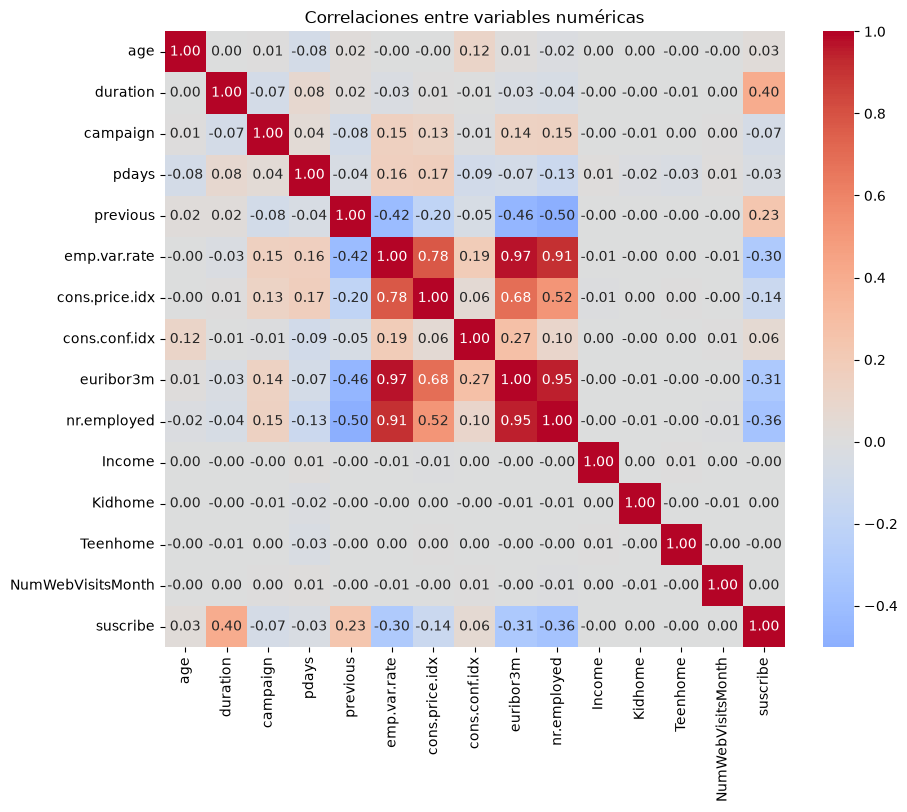

In [99]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numericas].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlaciones entre variables numéricas')
plt.savefig('../graficos/correlaciones.png', dpi=150, bbox_inches='tight')
plt.show()


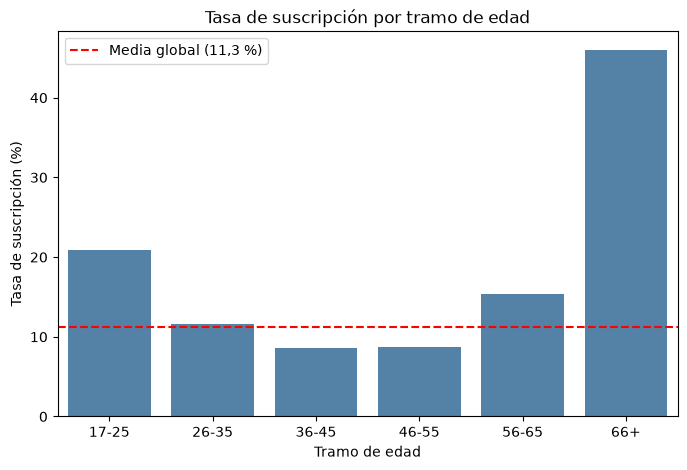

In [100]:
tasa_edad = reales.groupby('grupo_edad', observed=True)['suscribe'].mean() * 100

plt.figure(figsize=(8, 5))
sns.barplot(x=tasa_edad.index, y=tasa_edad.values, color='steelblue')
plt.axhline(df['suscribe'].mean() * 100, color='red', linestyle='--', label='Media global (11,3 %)')
plt.xlabel('Tramo de edad')
plt.ylabel('Tasa de suscripción (%)')
plt.title('Tasa de suscripción por tramo de edad')
plt.legend()
plt.savefig('../graficos/tasa_grupo_edad.png', dpi=150, bbox_inches='tight')
plt.show()


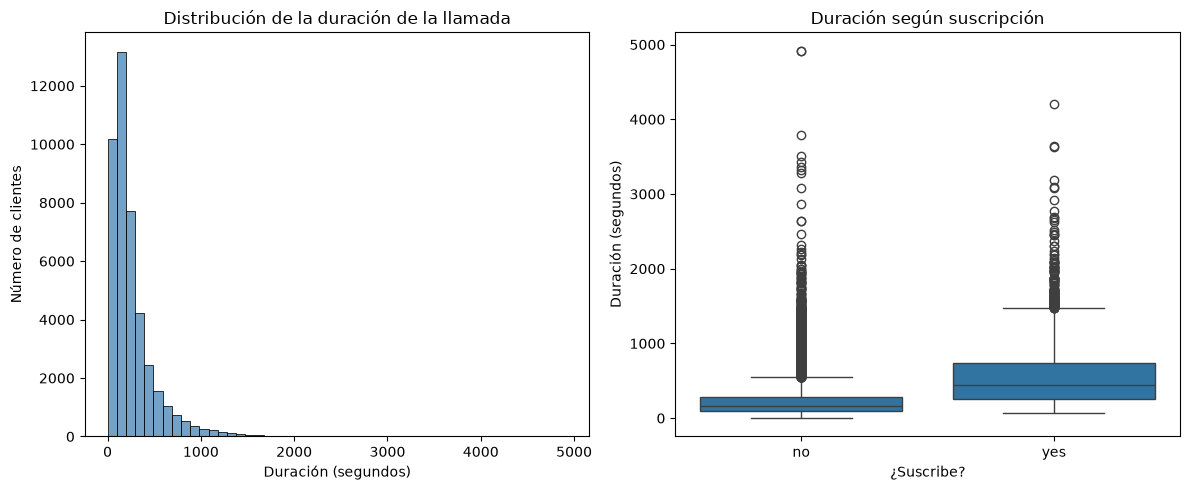

In [101]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['duration'], bins=50, ax=ejes[0], color='steelblue')
ejes[0].set_title('Distribución de la duración de la llamada')
ejes[0].set_xlabel('Duración (segundos)')
ejes[0].set_ylabel('Número de clientes')

sns.boxplot(data=df, x='y', y='duration', ax=ejes[1])
ejes[1].set_title('Duración según suscripción')
ejes[1].set_xlabel('¿Suscribe?')
ejes[1].set_ylabel('Duración (segundos)')

plt.tight_layout()
plt.savefig('../graficos/duracion.png', dpi=150, bbox_inches='tight')
plt.show()


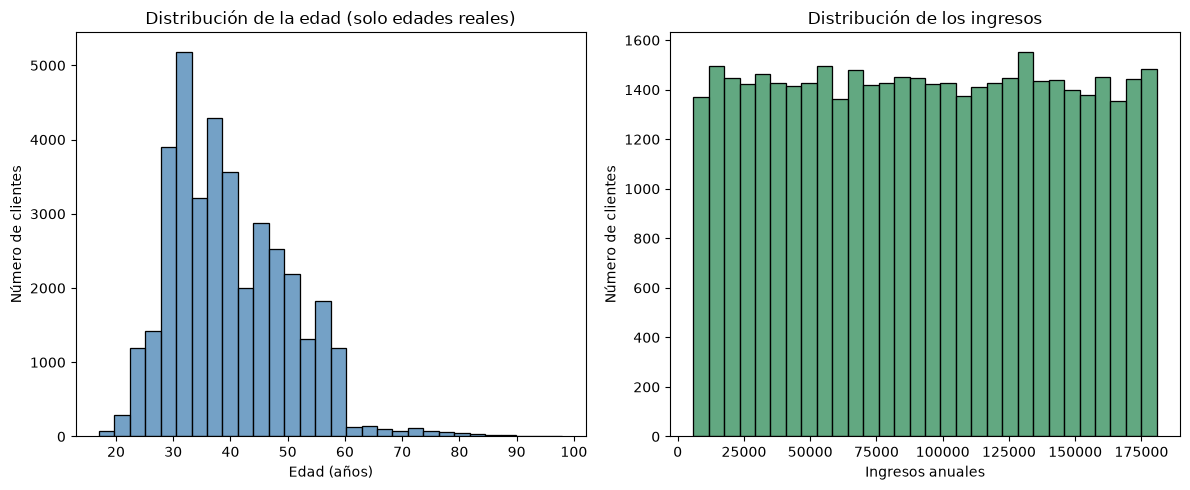

In [102]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(reales['age'], bins=30, ax=ejes[0], color='steelblue')
ejes[0].set_title('Distribución de la edad (solo edades reales)')
ejes[0].set_xlabel('Edad (años)')
ejes[0].set_ylabel('Número de clientes')

sns.histplot(df['Income'], bins=30, ax=ejes[1], color='seagreen')
ejes[1].set_title('Distribución de los ingresos')
ejes[1].set_xlabel('Ingresos anuales')
ejes[1].set_ylabel('Número de clientes')

plt.tight_layout()
plt.savefig('../graficos/edad_ingresos.png', dpi=150, bbox_inches='tight')
plt.show()


In [103]:

def grafico_tasa(columna, titulo):
    resumen = df.groupby(columna)['suscribe'].agg(['mean', 'count']).sort_values('mean', ascending=False)
    etiquetas = [f'{categoria} (n={n})' for categoria, n in zip(resumen.index, resumen['count'])]
    plt.figure(figsize=(9, 5))
    sns.barplot(x=resumen['mean'] * 100, y=etiquetas, orient='h', color='steelblue')
    plt.axvline(df['suscribe'].mean() * 100, color='red', linestyle='--', label='Media global (11,3 %)')
    plt.xlabel('Tasa de suscripción (%)')
    plt.ylabel('')
    plt.title(titulo)
    plt.legend()
    plt.savefig(f'../graficos/tasa_{columna}.png', dpi=150, bbox_inches='tight')
    plt.show()


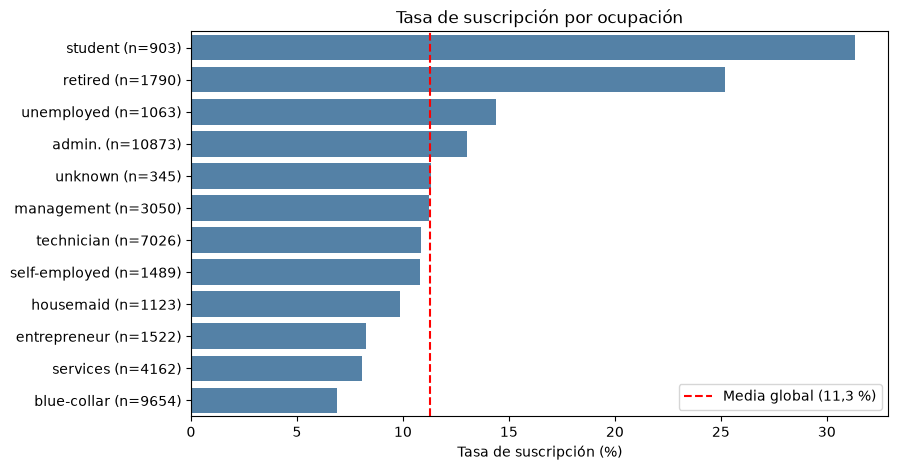

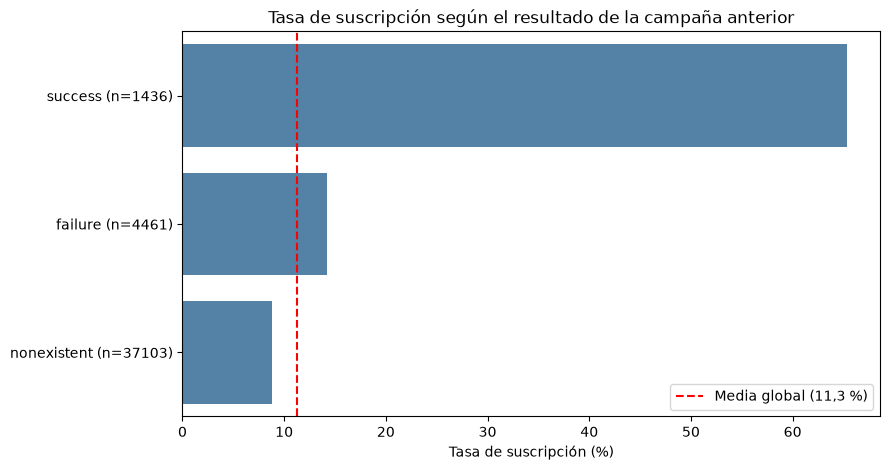

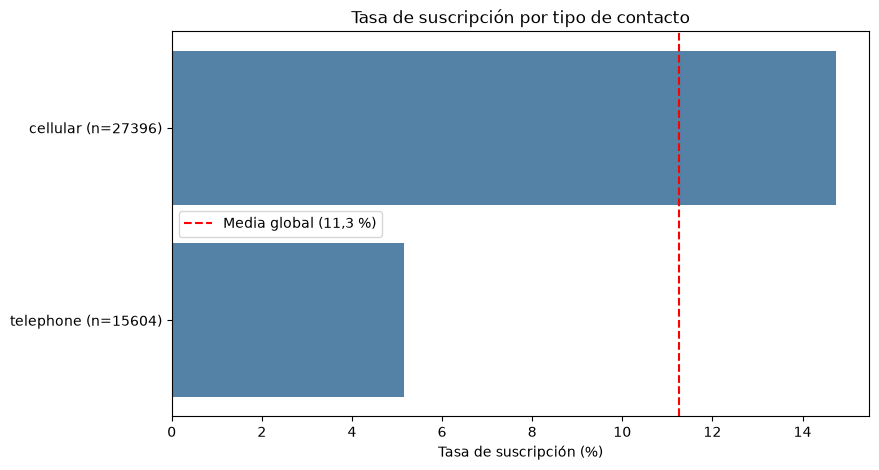

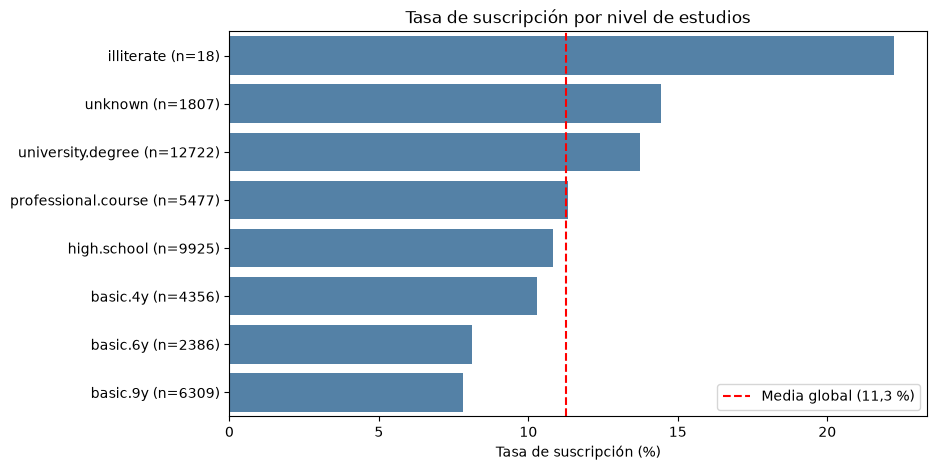

In [104]:
grafico_tasa('job', 'Tasa de suscripción por ocupación')
grafico_tasa('poutcome', 'Tasa de suscripción según el resultado de la campaña anterior')
grafico_tasa('contact', 'Tasa de suscripción por tipo de contacto')
grafico_tasa('education', 'Tasa de suscripción por nivel de estudios')


## 7. Conclusiones

- Solo el 11,3 % de los clientes suscribe el depósito, con grandes diferencias entre perfiles.
- Los perfiles más receptivos son los clientes que ya aceptaron antes (65 %), los mayores de 66 años (46 %), los estudiantes (31 %), los jubilados (25 %) y los contactados al móvil (14,7 %).
- La edad tiene forma de «U»: suscriben más los jóvenes y los mayores, y menos los de 36 a 55 años.
- La situación económica (`euribor3m`, `nr.employed`, `emp.var.rate`) se relaciona de forma moderada y negativa con suscribir.
- Ingresos, hijos, visitas web, hipoteca, préstamo y fecha de la llamada no explican la suscripción. Los datos del Excel parecen generados al azar.
- `duration` es la variable más ligada a suscribir, pero solo se conoce tras la llamada.

El informe completo, con las limitaciones y los gráficos, está en el `README.md`.
